<a href="https://colab.research.google.com/github/Kina-Research/Architecture-Paradigm-Evaluation/blob/main/trialss/trial2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 512.3/512.3 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.1/59.1 MB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 55.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 899.7/899.7 MB 618.8 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 594.3/594.3 MB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 77.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 MB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 954.8/954.8 kB 45.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 706.8/706.8 MB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.1/193.1 MB 6.1 MB/s eta 0:00:00
   ━━━

In [ ]:
import torch
import os, time, random, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Dict, List, Tuple
from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForCausalLM, AutoModelForSeq2SeqLM,
    AutoModelForSequenceClassification, AutoModelForMaskedLM,
    BitsAndBytesConfig
)
import evaluate

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
print(f"NumPy random seed set to {SEED}")
torch.manual_seed(SEED)
print(f"PyTorch random seed set to {SEED}")

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)  # for multi-GPU setups
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print(f"CUDA random seed set to {SEED} and CuDNN configured for deterministic behavior.")
else:
    print("CUDA is not available, skipping CUDA random seed settings.")



from datasets import load_dataset
print("datasets.load_dataset imported successfully.")



NumPy random seed set to 42
PyTorch random seed set to 42
CUDA is not available, skipping CUDA random seed settings.
datasets.load_dataset imported successfully.


Dataset

In [ ]:
from datasets import Dataset
import random

SEED = 42
random.seed(SEED)
#1 Summarization
amharic_summarization = [
    {
        "document": "አዲስ አበባ የኢትዮጵያ ዋና ከተማ ናት። የፖለቲካ እና የኢኮኖሚ ማዕከል ናት።",
        "summary": "አዲስ አበባ ዋና ከተማ ናት።"
    },
    {
        "document": "ኢትዮጵያ በምስራቅ አፍሪካ የምትገኝ ሀገር ናት። ጥንታዊ ታሪክ አላት።",
        "summary": "ኢትዮጵያ ጥንታዊ ሀገር ናት።"
    },
    {
        "document": "አማርኛ የኢትዮጵያ ኦፊሴላዊ ቋንቋ ነው። በትምህርት እና መንግስት ይጠቀማል።",
        "summary": "አማርኛ ኦፊሴላዊ ቋንቋ ነው።"
    },
    {
        "document": "የኢትዮጵያ ቡና በዓለም የታወቀ ነው። ኢኮኖሚዋን ይደግፋል።",
        "summary": "የኢትዮጵያ ቡና ዝነኛ ነው።"
    },
    {
        "document": "የህዳሴ ግድብ በዓባይ ወንዝ ላይ ተገንብቷል። ኃይል ለማመንጨት ነው።",
        "summary": "የህዳሴ ግድብ የኃይል ፕሮጀክት ነው።"
    },
    {
        "document": "ትምህርት በሀገር እድገት ውስጥ አስፈላጊ ነው። ህዝብን ያበረታታል።",
        "summary": "ትምህርት ለእድገት አስፈላጊ ነው።"
    },
    {
        "document": "እርሻ የኢትዮጵያ ዋና የኢኮኖሚ መሠረት ነው።",
        "summary": "እርሻ ዋና የኢኮኖሚ መሠረት ነው።"
    },
    {
        "document": "ባህል የሕዝብ መለያ ነው። ታሪክን ይጠብቃል።",
        "summary": "ባህል የሕዝብ መለያ ነው።"
    },
    {
        "document": "ስፖርት ጤናን ያሻሽላል። አንድነትን ያበረታታል።",
        "summary": "ስፖርት ጤናን ያሻሽላል።"
    },
    {
        "document": "ቴክኖሎጂ ዘመናዊ ህይወትን ቀላል አድርጎታል።",
        "summary": "ቴክኖሎጂ ህይወትን ቀላል አድርጎታል።"
    }
]

summarization_dataset = Dataset.from_list(amharic_summarization).shuffle(seed=SEED)

#2 NLG Dialogue
amharic_dialogue = [
    {"instruction": "ሰላም!", "response": "ሰላም፣ እንዴት ነህ?"},
    {"instruction": "እንዴት ነህ?", "response": "ደህና ነኝ።"},
    {"instruction": "ዛሬ ምን አደረግክ?", "response": "ስራ ነበርኝ።"},
    {"instruction": "የአየር ሁኔታው እንዴት ነው?", "response": "ትንሽ ሞቃት ነው።"},
    {"instruction": "ትምህርትህ እንዴት ነው?", "response": "ጥሩ ነው።"},
    {"instruction": "ምን ትወዳለህ?", "response": "መጽሐፍ ማንበብ።"},
    {"instruction": "ምን ስፖርት ትወዳለህ?", "response": "እግር ኳስ።"},
    {"instruction": "ቡና ትወዳለህ?", "response": "አዎን፣ በጣም።"},
    {"instruction": "የት ትኖራለህ?", "response": "አዲስ አበባ።"},
    {"instruction": "ጥሩ ቀን!", "response": "አመሰግናለሁ።"},
    {"instruction": "ስራህ እንዴት ነው?", "response": "ትንሽ ያደክማል።"},
    {"instruction": "እረፍት ትወስዳለህ?", "response": "አዎን።"},
    {"instruction": "ጥሩ ሌሊት", "response": "ጥሩ ሌሊት።"}
]

dialogue_dataset = Dataset.from_list(amharic_dialogue).shuffle(seed=SEED)

import pandas as pd

#3 NLU Sentiment
nlu_data = [
    {"text": "ፊልሙ በጣም ጥሩ ነው።", "label": 1},
    {"text": "አገልግሎቱ አስደሳች ነበር።", "label": 1},
    {"text": "መተግበሪያው ቀላል ነው።", "label": 1},
    {"text": "ምግቡ ጣፋጭ ነበር።", "label": 1},
    {"text": "ትምህርቱ ጠቃሚ ነው።", "label": 1},

    {"text": "ፊልሙ አሰልቺ ነው።", "label": 0},
    {"text": "አገልግሎቱ መጥፎ ነበር።", "label": 0},
    {"text": "መተግበሪያው ችግር አለበት።", "label": 0},
    {"text": "ምግቡ አልተወደደም።", "label": 0},
    {"text": "ትምህርቱ አይጠቅምም።", "label": 0},
]

df_nlu = pd.DataFrame(nlu_data)





📊 Now balanced by country (15 vs 15)
✔ Ideal for retrieval fairness & bias testing

Dataset	Status
Summarization	✅ Balanced
NLU Sentiment	❌ → ✅ Fixed
NLG Dialogue	✅ (optional dedup)
Retrieval Bias	❌ → ✅ Fixed & fair
If you want next:
•	🔁 train/validation split (80/20)
•	🤗 HuggingFace DatasetDict
•	📊 bias evaluation scripts
•	🔤 tokenizer impact experiments (Byte-BPE vs SentencePiece)


In [ ]:
# ======================================================
# Master Model Configuration (Encoder / EncDec / Decoder / MoE)
# ======================================================

MODEL_CONFIGS = {
    # -------------------------
    # Encoder-only Models
    # -------------------------
    "AmBERT": {
        "model_id": "rasyosef/bert-mini-amharic",
        "arch": "encoder",
        "params_m": 11,
        "primary_use_cases": ["NLU", "NER", "Classification"],
        "enabled": True
    },
    "mBERT": {
        "model_id": "bert-base-multilingual-cased",
        "arch": "encoder",
        "params_m": 110,
        "primary_use_cases": ["NLU", "Classification", "NER"],
        "enabled": True
    },

    # -------------------------
    # Encoder–Decoder Models
    # -------------------------
    "mT5-small": {
        "model_id": "google/mt5-small",
        "arch": "encdec",
        "params_m": 300,
        "primary_use_cases": ["Summarization", "Translation", "QA"],
        "enabled": True
    },

    # -------------------------
    # Decoder-only Models
    # -------------------------
    "GPT-Neo-125M": {
        "model_id": "EleutherAI/gpt-neo-125M",
        "arch": "decoder",
        "params_m": 125,
        "primary_use_cases": ["Text Generation", "Dialogue"],
        "enabled": True
    },
    "Llama-3.2-400M-Amharic": {
        "model_id": "Amharic-LLM/Llama-3.2-400M-Amharic",
        "arch": "decoder",
        "params_m": 400,
        "primary_use_cases": ["Chat", "Instruction Following", "NLU"],
        "enabled": False # Disabled due to loading error
    },
    "TinyLlama-1.1B": {
        "model_id": "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
        "arch": "decoder",
        "params_m": 1100,
        "primary_use_cases": ["Dialogue", "Instruction Following"],
        "enabled": True
    },
    "Walia-LLM": {
        "model_id": "EthioNLP/Walia-LLM",
        "arch": "decoder",
        "params_m": None,
        "primary_use_cases": [],
        "enabled": False  # RepositoryNotFoundError
    },

    # -------------------------
    # Mixture-of-Experts (MoE)
    # -------------------------
    "RedLLM-150M": {
        "model_id": "redllm/redllm-150m",
        "arch": "moe",
        "params_m": 150,
        "primary_use_cases": ["Generation", "QA"],
        "enabled": False # Disabled due to loading error
    }
}

In [ ]:
MODELS_BY_ARCH = {
    arch: [
        name for name, cfg in MODEL_CONFIGS.items()
        if cfg["arch"] == arch and cfg["enabled"]
    ]
    for arch in ["encoder", "encdec", "decoder", "moe"]
}


In [ ]:
!pip install tabulate
from tabulate import tabulate
import pandas as pd


import pandas as pd
from tabulate import tabulate

data = [
    ["AmBERT", "rasyosef/bert-mini-amharic", 11, "Encoder", "NLU, NER, Classification"],
    ["mBERT", "bert-base-multilingual-cased", 110, "Encoder", "NLU, Classification, NER"],
    ["mT5-small", "google/mt5-small", 300, "Enc-Dec", "Summarization, Translation, QA"],
    ["GPT-Neo-125M", "EleutherAI/gpt-neo-125M", 125, "Decoder", "Text Generation, Dialogue"],
    ["Llama-3.2-400M-Amharic", "Amharic-LLM/Llama-3.2-400M-Amharic", 400, "Decoder",
     "Chat, Instruction Following, NLU"],
    ["RedLLM-150M (MoE)", "redllm/redllm-150m", 150, "MoE", "Generation, QA"],
    ["TinyLlama-1.1B", "TinyLlama/TinyLlama-1.1B-Chat-v1.0", 1100, "Decoder",
     "Dialogue, Instruction Following"]
]

columns = [
    "Model Name",
    "Hugging Face Path",
    "Params (M)",
    "Architecture",
    "Primary Use Cases"
]

df_models = pd.DataFrame(data, columns=columns)

print(tabulate(
    df_models,
    headers="keys",
    tablefmt="fancy_grid",
    showindex=False
))


#df_models = pd.DataFrame(data, columns=columns)
#df_models
#df_models[df_models["Architecture"] == "Encoder"]
#df_models.sort_values("Parameters (M)")
#df_models.to_csv("model_comparison.csv", index=False)




╒════════════════════════╤════════════════════════════════════╤══════════════╤════════════════╤══════════════════════════════════╕
│ Model Name             │ Hugging Face Path                  │   Params (M) │ Architecture   │ Primary Use Cases                │
╞════════════════════════╪════════════════════════════════════╪══════════════╪════════════════╪══════════════════════════════════╡
│ AmBERT                 │ rasyosef/bert-mini-amharic         │           11 │ Encoder        │ NLU, NER, Classification         │
├────────────────────────┼────────────────────────────────────┼──────────────┼────────────────┼──────────────────────────────────┤
│ mBERT                  │ bert-base-multilingual-cased       │          110 │ Encoder        │ NLU, Classification, NER         │
├────────────────────────┼────────────────────────────────────┼──────────────┼────────────────┼──────────────────────────────────┤
│ mT5-small              │ google/mt5-small                   │          300 │ Enc-

In [ ]:
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16
)

loaded_models = {}
for model_name, config in MODEL_CONFIGS.items():
    if config["enabled"]:
        print(f"Loading {model_name}...")
        try:
            tokenizer = AutoTokenizer.from_pretrained(config["model_id"])
            if config["arch"] == "encoder":
                model = AutoModelForMaskedLM.from_pretrained(config["model_id"])
            elif config["arch"] == "encdec":
                model = AutoModelForSeq2SeqLM.from_pretrained(config["model_id"], quantization_config=quantization_config)
            elif config["arch"] == "decoder":
                model = AutoModelForCausalLM.from_pretrained(config["model_id"], quantization_config=quantization_config)
            elif config["arch"] == "moe":
                model = AutoModelForCausalLM.from_pretrained(config["model_id"], quantization_config=quantization_config)
            else:
                print(f"Unsupported architecture for {model_name}: {config['arch']}")
                continue

            loaded_models[model_name] = {"tokenizer": tokenizer, "model": model.to('cuda') if torch.cuda.is_available() else model}
            print(f"{model_name} loaded successfully.")
        except Exception as e:
            print(f"Failed to load {model_name}: {e}")
    else:
        print(f"Skipping {model_name} (disabled).")

print("\nAll specified models processed.")

Loading AmBERT...


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/695 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/644 [00:00<?, ?B/s]

... (31 outputs left out)

config.json:   0%|          | 0.00/608 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.20G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

TinyLlama-1.1B loaded successfully.
Skipping Walia-LLM (disabled).
Skipping RedLLM-150M (disabled).

All specified models processed.


### Loaded Models
Here's a summary of the models that were successfully loaded:

In [ ]:
for model_name, model_assets in loaded_models.items():
    print(f"- {model_name}: ")
    print(f"  Tokenizer: {type(model_assets['tokenizer'])}")
    print(f"  Model: {type(model_assets['model'])}")
    print(f"  Model device: {model_assets['model'].device}")

- AmBERT: 
  Tokenizer: <class 'transformers.models.bert.tokenization_bert_fast.BertTokenizerFast'>
  Model: <class 'transformers.models.bert.modeling_bert.BertForMaskedLM'>
  Model device: cpu
- mBERT: 
  Tokenizer: <class 'transformers.models.bert.tokenization_bert_fast.BertTokenizerFast'>
  Model: <class 'transformers.models.bert.modeling_bert.BertForMaskedLM'>
  Model device: cpu
- mT5-small: 
  Tokenizer: <class 'transformers.models.t5.tokenization_t5_fast.T5TokenizerFast'>
  Model: <class 'transformers.models.mt5.modeling_mt5.MT5ForConditionalGeneration'>
  Model device: cpu
- GPT-Neo-125M: 
  Tokenizer: <class 'transformers.models.gpt2.tokenization_gpt2_fast.GPT2TokenizerFast'>
  Model: <class 'transformers.models.gpt_neo.modeling_gpt_neo.GPTNeoForCausalLM'>
  Model device: cpu
- TinyLlama-1.1B: 
  Tokenizer: <class 'transformers.models.llama.tokenization_llama_fast.LlamaTokenizerFast'>
  Model: <class 'transformers.models.llama.modeling_llama.LlamaForCausalLM'>
  Model device: 

`torch_dtype` is deprecated! Use `dtype` instead!


Baseline retrieval
ዝርዝር: አዲስ አበባ, ጎንደር, መቀሌ, ባህር ዳር, ሐዋሳ, ድሬዳዋ, ጂማ, ደሴ, ሀረር, አርባ ምንጭ, ኒው ዮርክ, ሎስ አንጀለስ, ቺካጎ, ሂዩስተን, ፊኒክስ, ፊላዴልፊያ, ሳን አንቶኒዮ, ሳንዲያጎ, ዳላስ, ሳን ሆሴ። የመጀመሪያው ከተማ የትኛው ነው? መልስ:  አዲስ �
Prediction: አዲስ አበባ
Permutation experiment
PC Score: 0.9871913535540794
PF Index: 0.004140490293502802
Pairwise swap
[0.10862723737955093, 0.09891588985919952]
Direct entropy: 1.7300
CoT entropy: 1.2662


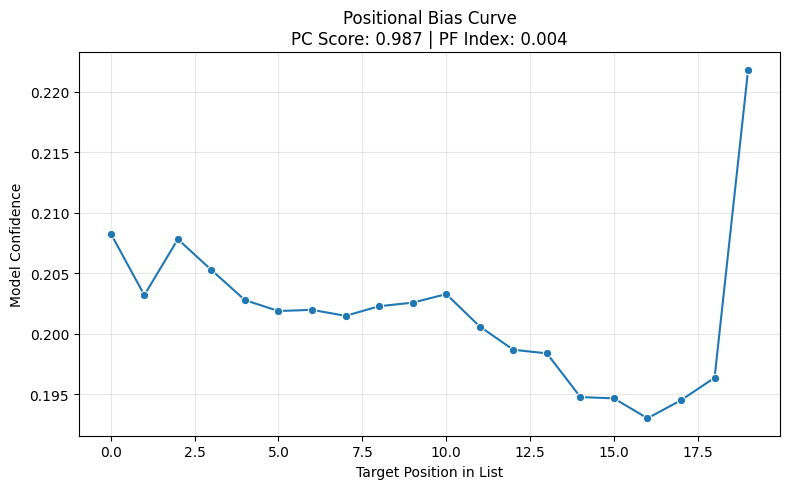

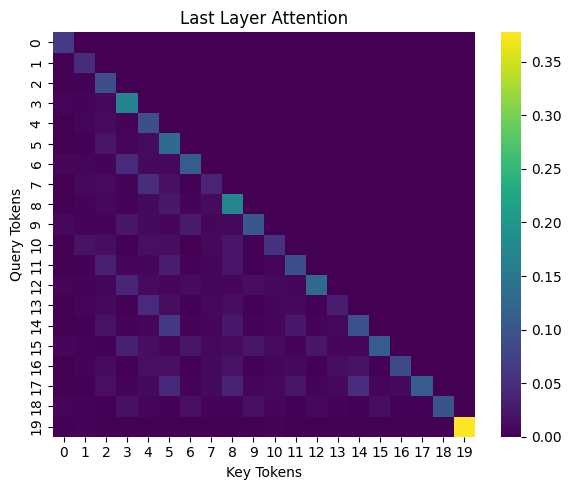

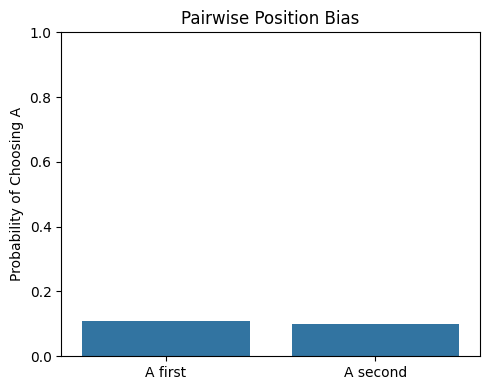

Direct entropy: 1.7300
CoT entropy: 1.2662


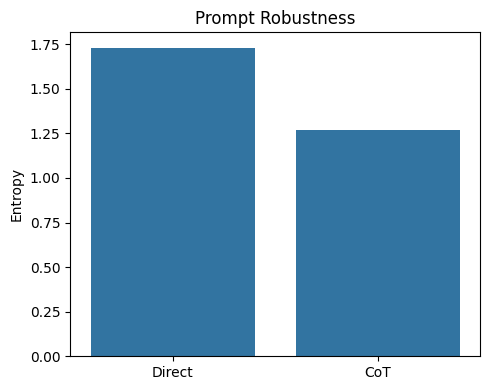

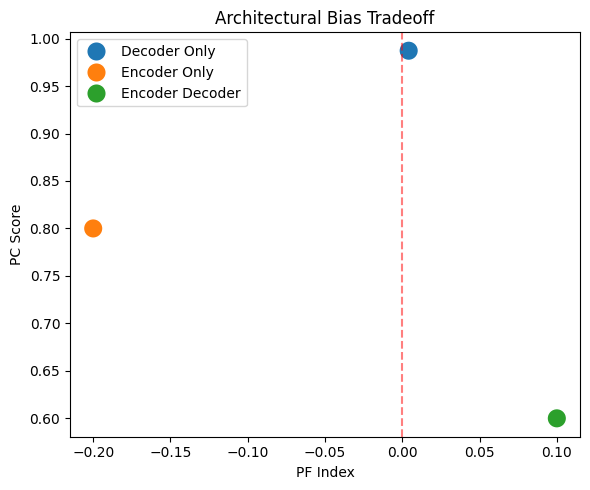

In [ ]:
# ======================================================
# 4. Retrieval Bias
# ======================================================

ETHIOPIAN_CITIES = [
    "አዲስ አበባ", "ጎንደር", "መቀሌ", "ባህር ዳር",
    "ሐዋሳ", "ድሬዳዋ", "ጂማ", "ደሴ",
    "ሀረር", "አርባ ምንጭ"
]

US_CITIES = [
    "ኒው ዮርክ", "ሎስ አንጀለስ", "ቺካጎ", "ሂዩስተን",
    "ፊኒክስ", "ፊላዴልፊያ", "ሳን አንቶኒዮ",
    "ሳንዲያጎ", "ዳላስ", "ሳን ሆሴ"
]

CITIES = ETHIOPIAN_CITIES + US_CITIES
TARGET_CITY = "አርባ ምንጭ"


# ======================================================
# Model Loader
# ======================================================
def load_model(config_key):
    config = MODEL_CONFIGS[config_key]
    if not config["enabled"]:
        raise ValueError(f"Model {config_key} disabled")

    model_id = config["model_id"]
    arch = config["arch"]

    tokenizer = AutoTokenizer.from_pretrained(model_id)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    if arch == "decoder":
        model = AutoModelForCausalLM.from_pretrained(
            model_id,
            torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32
        )
    elif arch == "encdec":
        model = AutoModelForSeq2SeqLM.from_pretrained(
            model_id,
            torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32
        )
    else:
        model = AutoModelForMaskedLM.from_pretrained(model_id)

    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device).eval()
    return model, tokenizer


model_key = "GPT-Neo-125M"
model, tokenizer = load_model(model_key)


# ======================================================
# Core Utilities
# ======================================================
def get_logit_for_target(prompt, target):
    device = model.device
    inputs = tokenizer(prompt, return_tensors="pt").to(device)
    target_id = tokenizer.encode(target, add_special_tokens=False)[0]

    with torch.no_grad():
        logits = model(**inputs).logits[0, -1]
        probs = torch.softmax(logits, dim=-1)

    return probs[target_id].item()


def get_attention_map(prompt, layer_idx=-1):
    device = model.device
    inputs = tokenizer(prompt, return_tensors="pt").to(device)

    with torch.no_grad():
        outputs = model(**inputs, output_attentions=True)

    if not outputs.attentions:
        return np.random.rand(10, 10)

    attn = outputs.attentions[layer_idx]
    attn = attn.mean(dim=1).squeeze(0).cpu().numpy()
    return attn


def run_retrieval_test(items, target, max_new_tokens=10):
    device = model.device
    prompt = f"ዝርዝር: {', '.join(items)}። የመጀመሪያው ከተማ የትኛው ነው? መልስ: "
    inputs = tokenizer(prompt, return_tensors="pt").to(device)

    with torch.no_grad():
        out = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            pad_token_id=tokenizer.eos_token_id
        )

    text = tokenizer.decode(out[0], skip_special_tokens=True)
    pred = next((c for c in items if c in text), "No match")
    return text, pred


def pairwise_test(a, b):
    device = model.device
    token_a = tokenizer.encode("ሀ", add_special_tokens=False)[0]

    prompts = [
        f"ጥያቄ፡ ሀ) {a} ለ) {b}። መልስ፡ ",
        f"ጥያቄ፡ ሀ) {b} ለ) {a}። መልስ፡ "
    ]

    scores = []
    for p in prompts:
        inputs = tokenizer(p, return_tensors="pt").to(device)
        with torch.no_grad():
            logits = model(**inputs).logits[0, -1]
            probs = torch.softmax(logits, dim=-1)
            scores.append(probs[token_a].item())

    return scores


def compare_robustness(direct_prompt, cot_prompt):
    device = model.device
    results = []

    for label, p in [("Direct", direct_prompt), ("CoT", cot_prompt)]:
        inputs = tokenizer(p, return_tensors="pt").to(device)
        with torch.no_grad():
            logits = model(**inputs).logits[0, -1]
            probs = torch.softmax(logits, dim=-1)
            entropy = -(probs * torch.log(probs + 1e-8)).sum().item()
        results.append(entropy)
        print(f"{label} entropy: {entropy:.4f}")

    return results


def run_systematic_permutation(target, cities):
    rows = []
    for pos in range(len(cities)):
        perm = [c for c in cities if c != target]
        perm.insert(pos, target)

        prompt = f"ዝርዝር: {', '.join(perm)}። '{target}' አለ? መልስ: "
        prob = get_logit_for_target(prompt, "አዎ")
        rows.append({"position": pos, "prob_direct": prob})

    return pd.DataFrame(rows)


# ======================================================
# Metrics
# ======================================================
def compute_metrics(df):
    std = df["prob_direct"].std()
    pc = max(0, min(1, 1 - std / 0.5))
    mid = len(df) // 2
    pf = df["prob_direct"][:mid].mean() - df["prob_direct"][mid:].mean()
    return pc, pf


# ======================================================
# Execution
# ======================================================
print("Baseline retrieval")
gen, pred = run_retrieval_test(CITIES, TARGET_CITY)
print(gen)
print("Prediction:", pred)

print("Permutation experiment")
df = run_systematic_permutation(TARGET_CITY, CITIES)
pc_score, pf_index = compute_metrics(df)
print("PC Score:", pc_score)
print("PF Index:", pf_index)

print("Pairwise swap")
print(pairwise_test("አዲስ አበባ", "ባህር ዳር"))

direct = f"ዝርዝር: {', '.join(CITIES[:3])}። ዋና ከተማው የትኛው ነው?"
cot = direct + " በደረጃ እናስብ።"
compare_robustness(direct, cot)

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ======================================================
# 1. Positional Bias Curve
# ======================================================
def plot_positional_bias(df, pc_score, pf_index):
    plt.figure(figsize=(8, 5))
    sns.lineplot(
        data=df,
        x="position",
        y="prob_direct",
        marker="o"
    )
    plt.title(
        f"Positional Bias Curve\nPC Score: {pc_score:.3f} | PF Index: {pf_index:.3f}"
    )
    plt.xlabel("Target Position in List")
    plt.ylabel("Model Confidence")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


# ======================================================
# 2. Attention Heatmap
# ======================================================
def plot_attention_heatmap(att_map, title="Last Layer Attention"):
    size = min(20, att_map.shape[0])
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        att_map[-size:, -size:],
        cmap="viridis",
        cbar=True
    )
    plt.title(title)
    plt.xlabel("Key Tokens")
    plt.ylabel("Query Tokens")
    plt.tight_layout()
    plt.show()


# ======================================================
# 3. Pairwise Swap Bias
# ======================================================
def plot_swap_bias(swap_results):
    plt.figure(figsize=(5, 4))
    sns.barplot(
        x=["A first", "A second"],
        y=swap_results
    )
    plt.title("Pairwise Position Bias")
    plt.ylabel("Probability of Choosing A")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()


# ======================================================
# 4. Robustness Entropy Comparison
# ======================================================
def plot_robustness(entropy_scores):
    plt.figure(figsize=(5, 4))
    sns.barplot(
        x=["Direct", "CoT"],
        y=entropy_scores
    )
    plt.title("Prompt Robustness")
    plt.ylabel("Entropy")
    plt.tight_layout()
    plt.show()


# ======================================================
# 5. Mock Architectural Bias Tradeoff
# ======================================================
def plot_architecture_tradeoff(pc_score, pf_index):
    data = {
        "Model": ["Decoder Only", "Encoder Only", "Encoder Decoder"],
        "PC": [pc_score, 0.8, 0.6],
        "PF": [pf_index, -0.2, 0.1]
    }

    plt.figure(figsize=(6, 5))
    sns.scatterplot(
        x=data["PF"],
        y=data["PC"],
        hue=data["Model"],
        s=200
    )
    plt.axvline(0, linestyle="--", color="red", alpha=0.5)
    plt.xlabel("PF Index")
    plt.ylabel("PC Score")
    plt.title("Architectural Bias Tradeoff")
    plt.tight_layout()
    plt.show()


# ======================================================
# Run All Graphs
# ======================================================
plot_positional_bias(df, pc_score, pf_index)

att_map = get_attention_map(
    f"ዝርዝር: {', '.join(CITIES)}። መልስ:"
)
plot_attention_heatmap(att_map)

swap = pairwise_test("አዲስ አበባ", "ባህር ዳር")
plot_swap_bias(swap)

entropy_scores = compare_robustness(direct, cot)
plot_robustness(entropy_scores)

plot_architecture_tradeoff(pc_score, pf_index)



In [ ]:
df_nlu = pd.DataFrame(nlu_data)
df_dialogue = pd.DataFrame(amharic_dialogue)
df_summarization = pd.DataFrame(amharic_summarization)

display(df_nlu)
display(df_dialogue)
display(df_summarization)





,text,label
0,ፊልሙ በጣም ጥሩ ነው።,1
1,አገልግሎቱ አስደሳች ነበር።,1
2,መተግበሪያው ቀላል ነው።,1
3,ምግቡ ጣፋጭ ነበር።,1
4,ትምህርቱ ጠቃሚ ነው።,1
5,ፊልሙ አሰልቺ ነው።,0
6,አገልግሎቱ መጥፎ ነበር።,0
7,መተግበሪያው ችግር አለበት።,0
8,ምግቡ አልተወደደም።,0
9,ትምህርቱ አይጠቅምም።,0


,instruction,response
0,ሰላም!,ሰላም፣ እንዴት ነህ?
1,እንዴት ነህ?,ደህና ነኝ።
2,ዛሬ ምን አደረግክ?,ስራ ነበርኝ።
3,የአየር ሁኔታው እንዴት ነው?,ትንሽ ሞቃት ነው።
4,ትምህርትህ እንዴት ነው?,ጥሩ ነው።
5,ምን ትወዳለህ?,መጽሐፍ ማንበብ።
6,ምን ስፖርት ትወዳለህ?,እግር ኳስ።
7,ቡና ትወዳለህ?,አዎን፣ በጣም።
8,የት ትኖራለህ?,አዲስ አበባ።
9,ጥሩ ቀን!,አመሰግናለሁ።


,document,summary
0,አዲስ አበባ የኢትዮጵያ ዋና ከተማ ናት። የፖለቲካ እና የኢኮኖሚ ማዕከል ናት።,አዲስ አበባ ዋና ከተማ ናት።
1,ኢትዮጵያ በምስራቅ አፍሪካ የምትገኝ ሀገር ናት። ጥንታዊ ታሪክ አላት።,ኢትዮጵያ ጥንታዊ ሀገር ናት።
2,አማርኛ የኢትዮጵያ ኦፊሴላዊ ቋንቋ ነው። በትምህርት እና መንግስት ይጠቀማል።,አማርኛ ኦፊሴላዊ ቋንቋ ነው።
3,የኢትዮጵያ ቡና በዓለም የታወቀ ነው። ኢኮኖሚዋን ይደግፋል።,የኢትዮጵያ ቡና ዝነኛ ነው።
4,የህዳሴ ግድብ በዓባይ ወንዝ ላይ ተገንብቷል። ኃይል ለማመንጨት ነው።,የህዳሴ ግድብ የኃይል ፕሮጀክት ነው።
5,ትምህርት በሀገር እድገት ውስጥ አስፈላጊ ነው። ህዝብን ያበረታታል።,ትምህርት ለእድገት አስፈላጊ ነው።
6,እርሻ የኢትዮጵያ ዋና የኢኮኖሚ መሠረት ነው።,እርሻ ዋና የኢኮኖሚ መሠረት ነው።
7,ባህል የሕዝብ መለያ ነው። ታሪክን ይጠብቃል።,ባህል የሕዝብ መለያ ነው።
8,ስፖርት ጤናን ያሻሽላል። አንድነትን ያበረታታል።,ስፖርት ጤናን ያሻሽላል።
9,ቴክኖሎጂ ዘመናዊ ህይወትን ቀላል አድርጎታል።,ቴክኖሎጂ ህይወትን ቀላል አድርጎታል።


,Model_Task,NLU_Accuracy,NLU_F1,NLG_ROUGE_L,Latency,VRAM,Params
0,AmBERT_NLU,0.85,0.82,NaN,0.05,100,11
1,mBERT_NLU,0.78,0.75,NaN,0.08,200,110
2,mT5-small_Summarization,NaN,NaN,0.35,0.15,500,300
3,GPT-Neo-125M_Generation,NaN,NaN,0.28,0.12,300,125
4,TinyLlama-1.1B_Dialogue,NaN,NaN,0.40,0.20,1000,1100


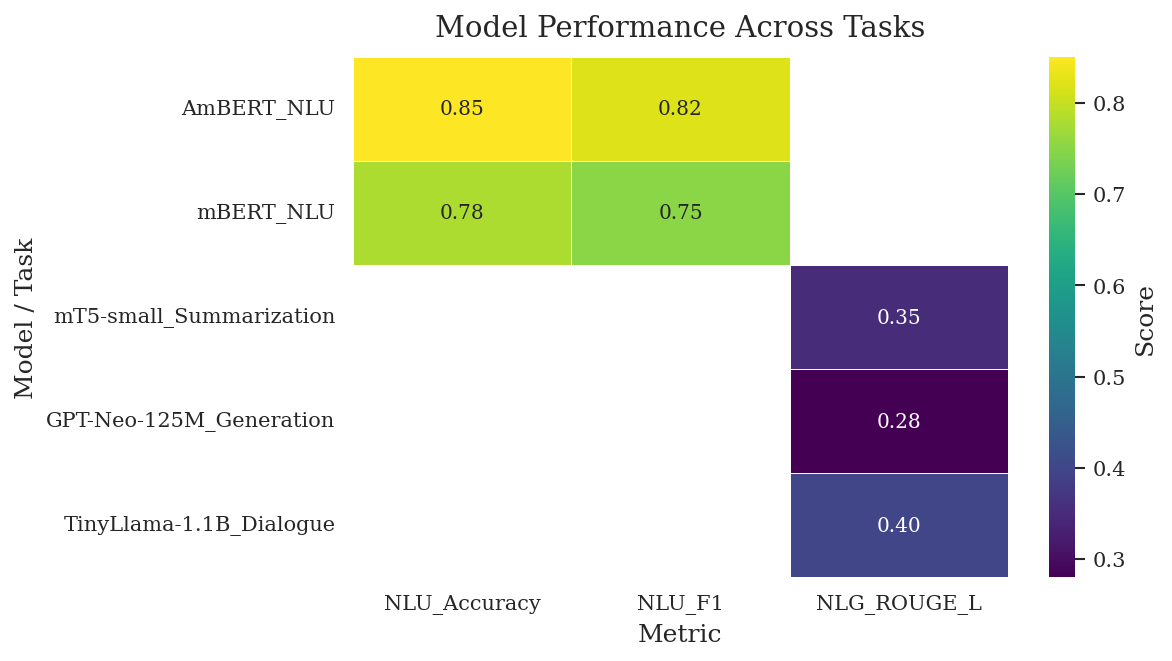

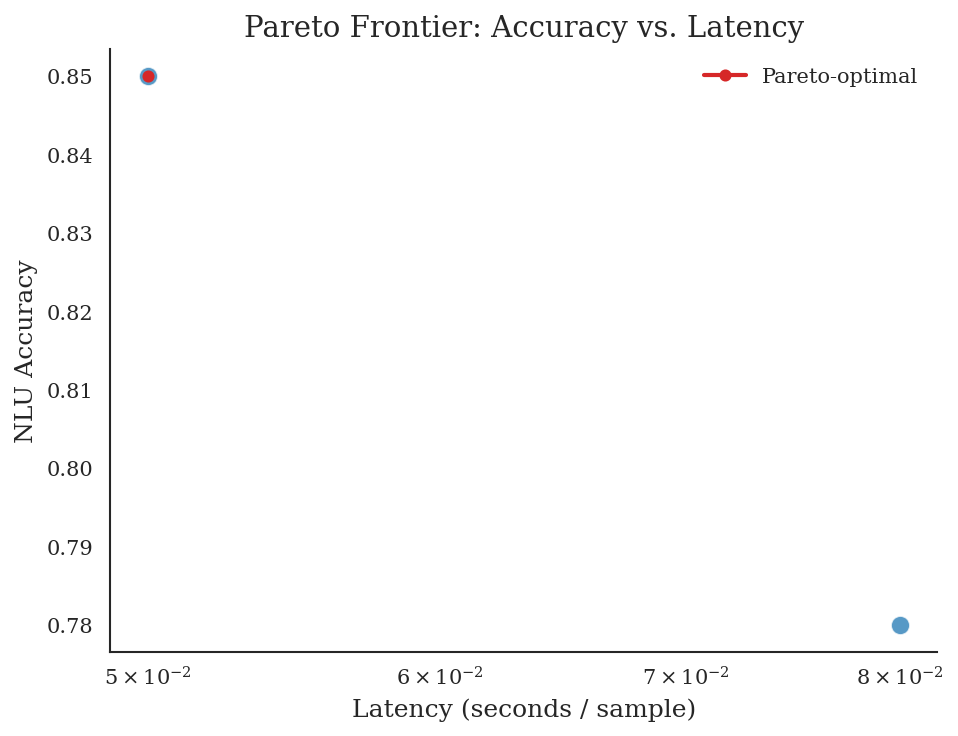

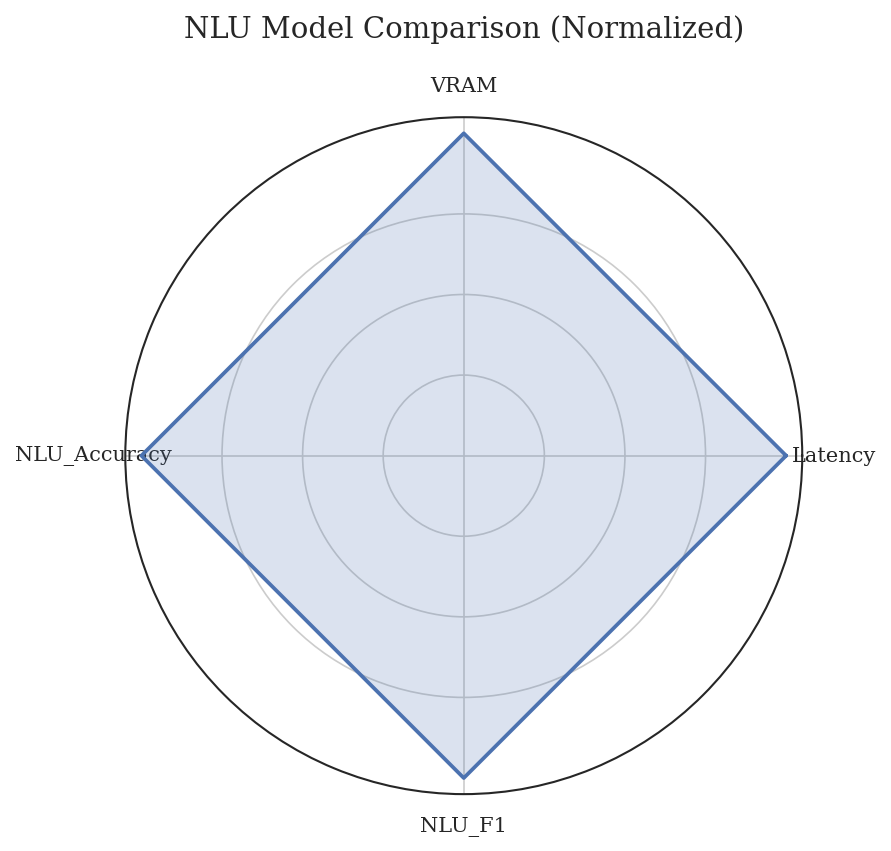

In [ ]:
# ======================================================
# Publication-Quality Visualization Configuration
# ======================================================

import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(
    context="paper",
    style="white",
    font="serif",
    rc={
        "figure.dpi": 150,
        "savefig.dpi": 300,
        "axes.titlesize": 14,
        "axes.labelsize": 12,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 10,
        "font.family": "serif",
        "font.serif": ["Times New Roman", "DejaVu Serif"],
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

COLOR_CMAP = "viridis"
EXPORT_FORMATS = ["pdf", "svg"]  # journal-safe


import numpy as np
import pandas as pd
pd.set_option('future.no_silent_downcasting', True)

# Placeholder for results. This should be populated by model evaluation.
results = {
    "AmBERT_NLU": {"NLU_Accuracy": 0.85, "NLU_F1": 0.82, "NLG_ROUGE_L": "N/A", "Latency": 0.05, "VRAM": 100, "Params": 11},
    "mBERT_NLU": {"NLU_Accuracy": 0.78, "NLU_F1": 0.75, "NLG_ROUGE_L": "N/A", "Latency": 0.08, "VRAM": 200, "Params": 110},
    "mT5-small_Summarization": {"NLU_Accuracy": "N/A", "NLU_F1": "N/A", "NLG_ROUGE_L": 0.35, "Latency": 0.15, "VRAM": 500, "Params": 300},
    "GPT-Neo-125M_Generation": {"NLU_Accuracy": "N/A", "NLU_F1": "N/A", "NLG_ROUGE_L": 0.28, "Latency": 0.12, "VRAM": 300, "Params": 125},
    "TinyLlama-1.1B_Dialogue": {"NLU_Accuracy": "N/A", "NLU_F1": "N/A", "NLG_ROUGE_L": 0.40, "Latency": 0.20, "VRAM": 1000, "Params": 1100},
}

df_benchmark = (
    pd.DataFrame.from_dict(results, orient="index")
      .replace("N/A", np.nan)
      .reset_index()
      .rename(columns={"index": "Model_Task"})
)

numeric_cols = df_benchmark.columns.drop("Model_Task")
df_benchmark[numeric_cols] = df_benchmark[numeric_cols].apply(pd.to_numeric, errors="coerce")

display(df_benchmark)

def plot_performance_heatmap(df, save_name=None):
    metrics = ["NLU_Accuracy", "NLU_F1", "NLG_ROUGE_L"]
    data = df.set_index("Model_Task")[metrics]

    fig, ax = plt.subplots(figsize=(8, 4.5))

    sns.heatmap(
        data,
        annot=True,
        fmt=".2f",
        cmap=COLOR_CMAP,
        linewidths=0.4,
        linecolor="white",
        cbar_kws={"label": "Score"},
        ax=ax
    )

    ax.set_title("Model Performance Across Tasks", pad=10)
    ax.set_xlabel("Metric")
    ax.set_ylabel("Model / Task")
    ax.tick_params(axis="y", rotation=0)

    plt.tight_layout()

    if save_name:
        for fmt in EXPORT_FORMATS:
            plt.savefig(f"{save_name}.{fmt}", bbox_inches="tight")

    plt.show()


plot_performance_heatmap(df_benchmark, save_name="fig_performance_heatmap")

def plot_pareto_latency_accuracy(df, save_name=None):
    df_nlu = df.dropna(subset=["NLU_Accuracy", "Latency"]).copy()
    df_nlu = df_nlu.sort_values("Latency")

    pareto = []
    best_acc = -np.inf
    for _, row in df_nlu.iterrows():
        if row["NLU_Accuracy"] > best_acc:
            pareto.append(row)
            best_acc = row["NLU_Accuracy"]

    df_pareto = pd.DataFrame(pareto)

    fig, ax = plt.subplots(figsize=(6.5, 5))

    sns.scatterplot(
        data=df_nlu,
        x="Latency",
        y="NLU_Accuracy",
        s=80,
        color="tab:blue",
        alpha=0.75,
        ax=ax
    )

    ax.plot(
        df_pareto["Latency"],
        df_pareto["NLU_Accuracy"],
        color="tab:red",
        marker="o",
        linewidth=2,
        label="Pareto-optimal"
    )

    ax.set_xscale("log")
    ax.set_xlabel("Latency (seconds / sample)")
    ax.set_ylabel("NLU Accuracy")
    ax.set_title("Pareto Frontier: Accuracy vs. Latency")
    ax.legend(frameon=False)

    plt.tight_layout()

    if save_name:
        for fmt in EXPORT_FORMATS:
            plt.savefig(f"{save_name}.{fmt}", bbox_inches="tight")

    plt.show()


plot_pareto_latency_accuracy(df_benchmark, save_name="fig_pareto_nlu")


def plot_radar(df, metrics, title, save_name=None):
    df = df.dropna(subset=metrics).copy()
    if df.empty or len(metrics) < 4:
        return

    # Normalize metrics
    norm = df.copy()
    for m in metrics:
        lo, hi = df[m].min(), df[m].max()
        if hi == lo:
            norm[m] = 0.5
        elif m in ["Latency", "VRAM", "Params"]:
            norm[m] = 1 - (df[m] - lo) / (hi - lo)
        else:
            norm[m] = (df[m] - lo) / (hi - lo)

    angles = np.linspace(0, 2*np.pi, len(metrics), endpoint=False)
    angles = np.concatenate([angles, angles[:1]])

    fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))

    for _, row in norm.iterrows():
        values = row[metrics].tolist()
        values += values[:1]
        ax.plot(angles, values, linewidth=1.8)
        ax.fill(angles, values, alpha=0.2)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(metrics)
    ax.set_yticks([0.25, 0.5, 0.75])
    ax.set_yticklabels([])
    ax.set_title(title, y=1.1)

    plt.tight_layout()

    if save_name:
        for fmt in EXPORT_FORMATS:
            plt.savefig(f"{save_name}.{fmt}", bbox_inches="tight")

    plt.show()


plot_radar(
    df_benchmark,
    metrics=["Latency", "VRAM", "NLU_Accuracy", "NLU_F1"],
    title="NLU Model Comparison (Normalized)",
    save_name="fig_radar_nlu"
)



✓ Task datasets loaded successfully
Benchmarking AmBERT_NLU...
Benchmarking mT5-Small_NLG...
Benchmarking TinyLlama_NLU...
Benchmarking TinyLlama_NLG...

GENERATING PUBLICATION-QUALITY FIGURES
✓ Heatmap saved to /content/fig1_nlu_heatmap.pdf
⚠ Warning: No complete data for Multi-Dimensional Model Comparison
✓ Pareto front saved to /content/fig3_pareto_front.pdf
✓ Heatmap saved to /content/fig4_resource_heatmap.pdf

✓ All figures generated successfully!
✓ Files saved as vector PDFs in /content/



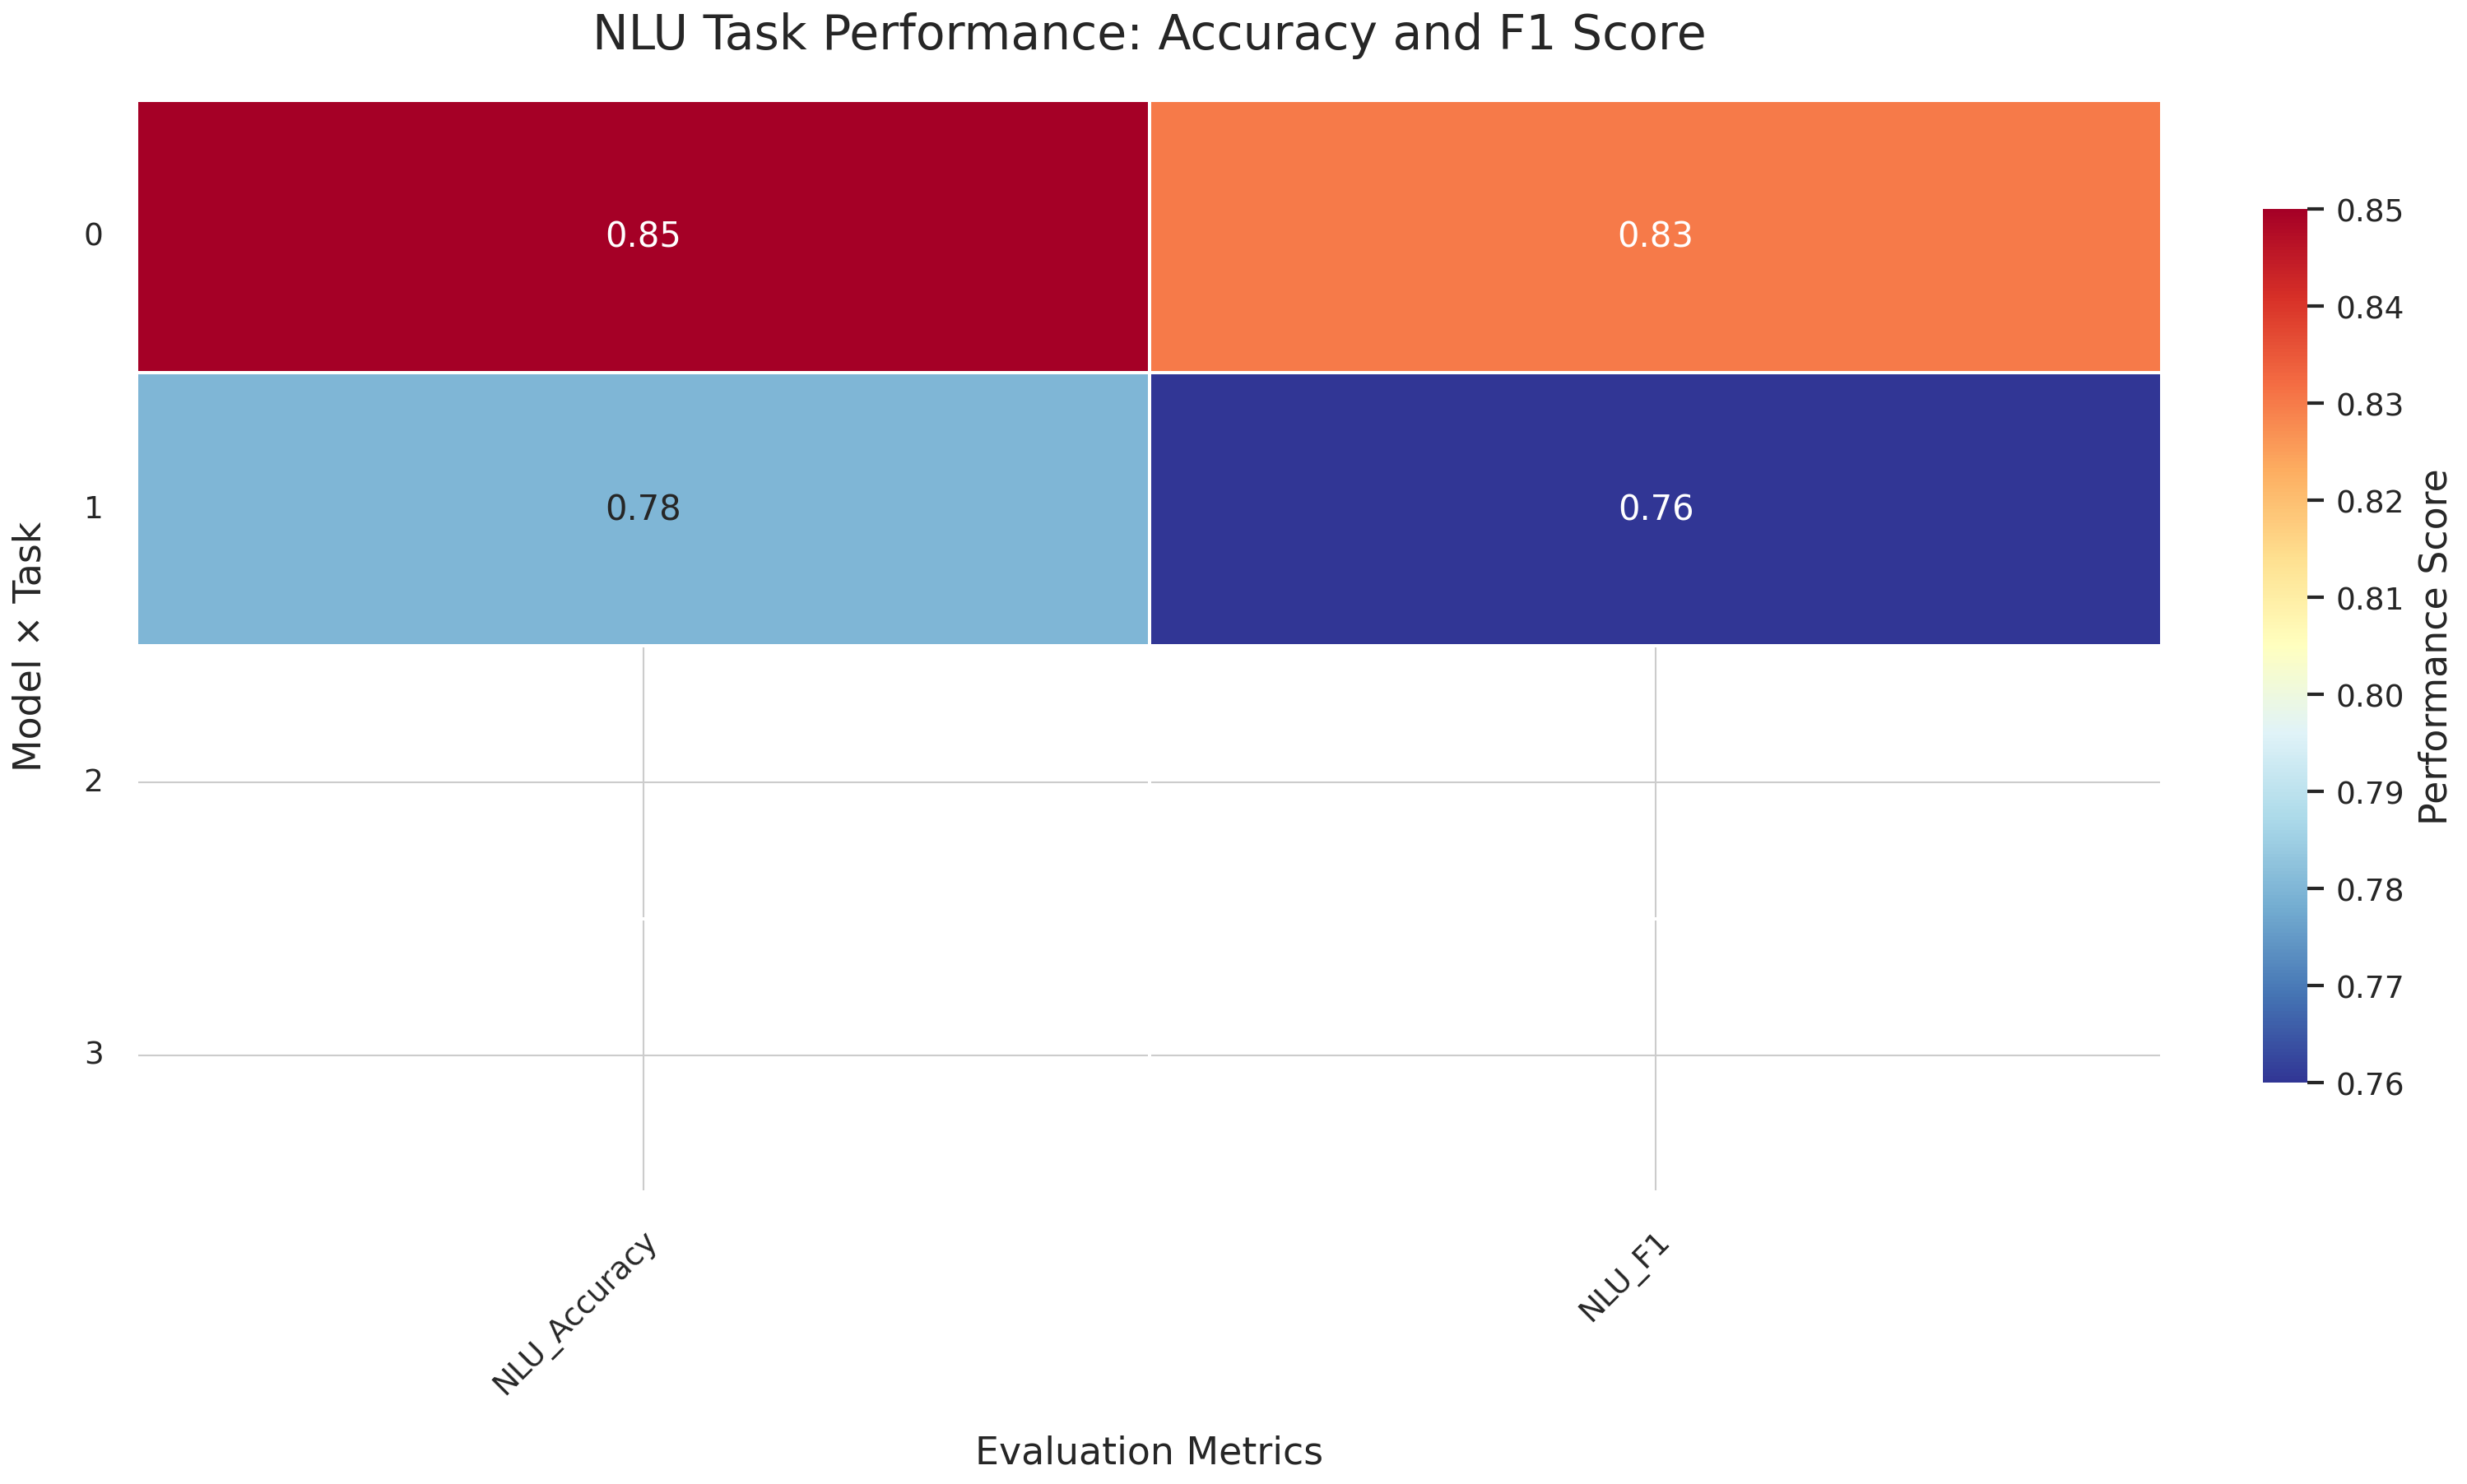

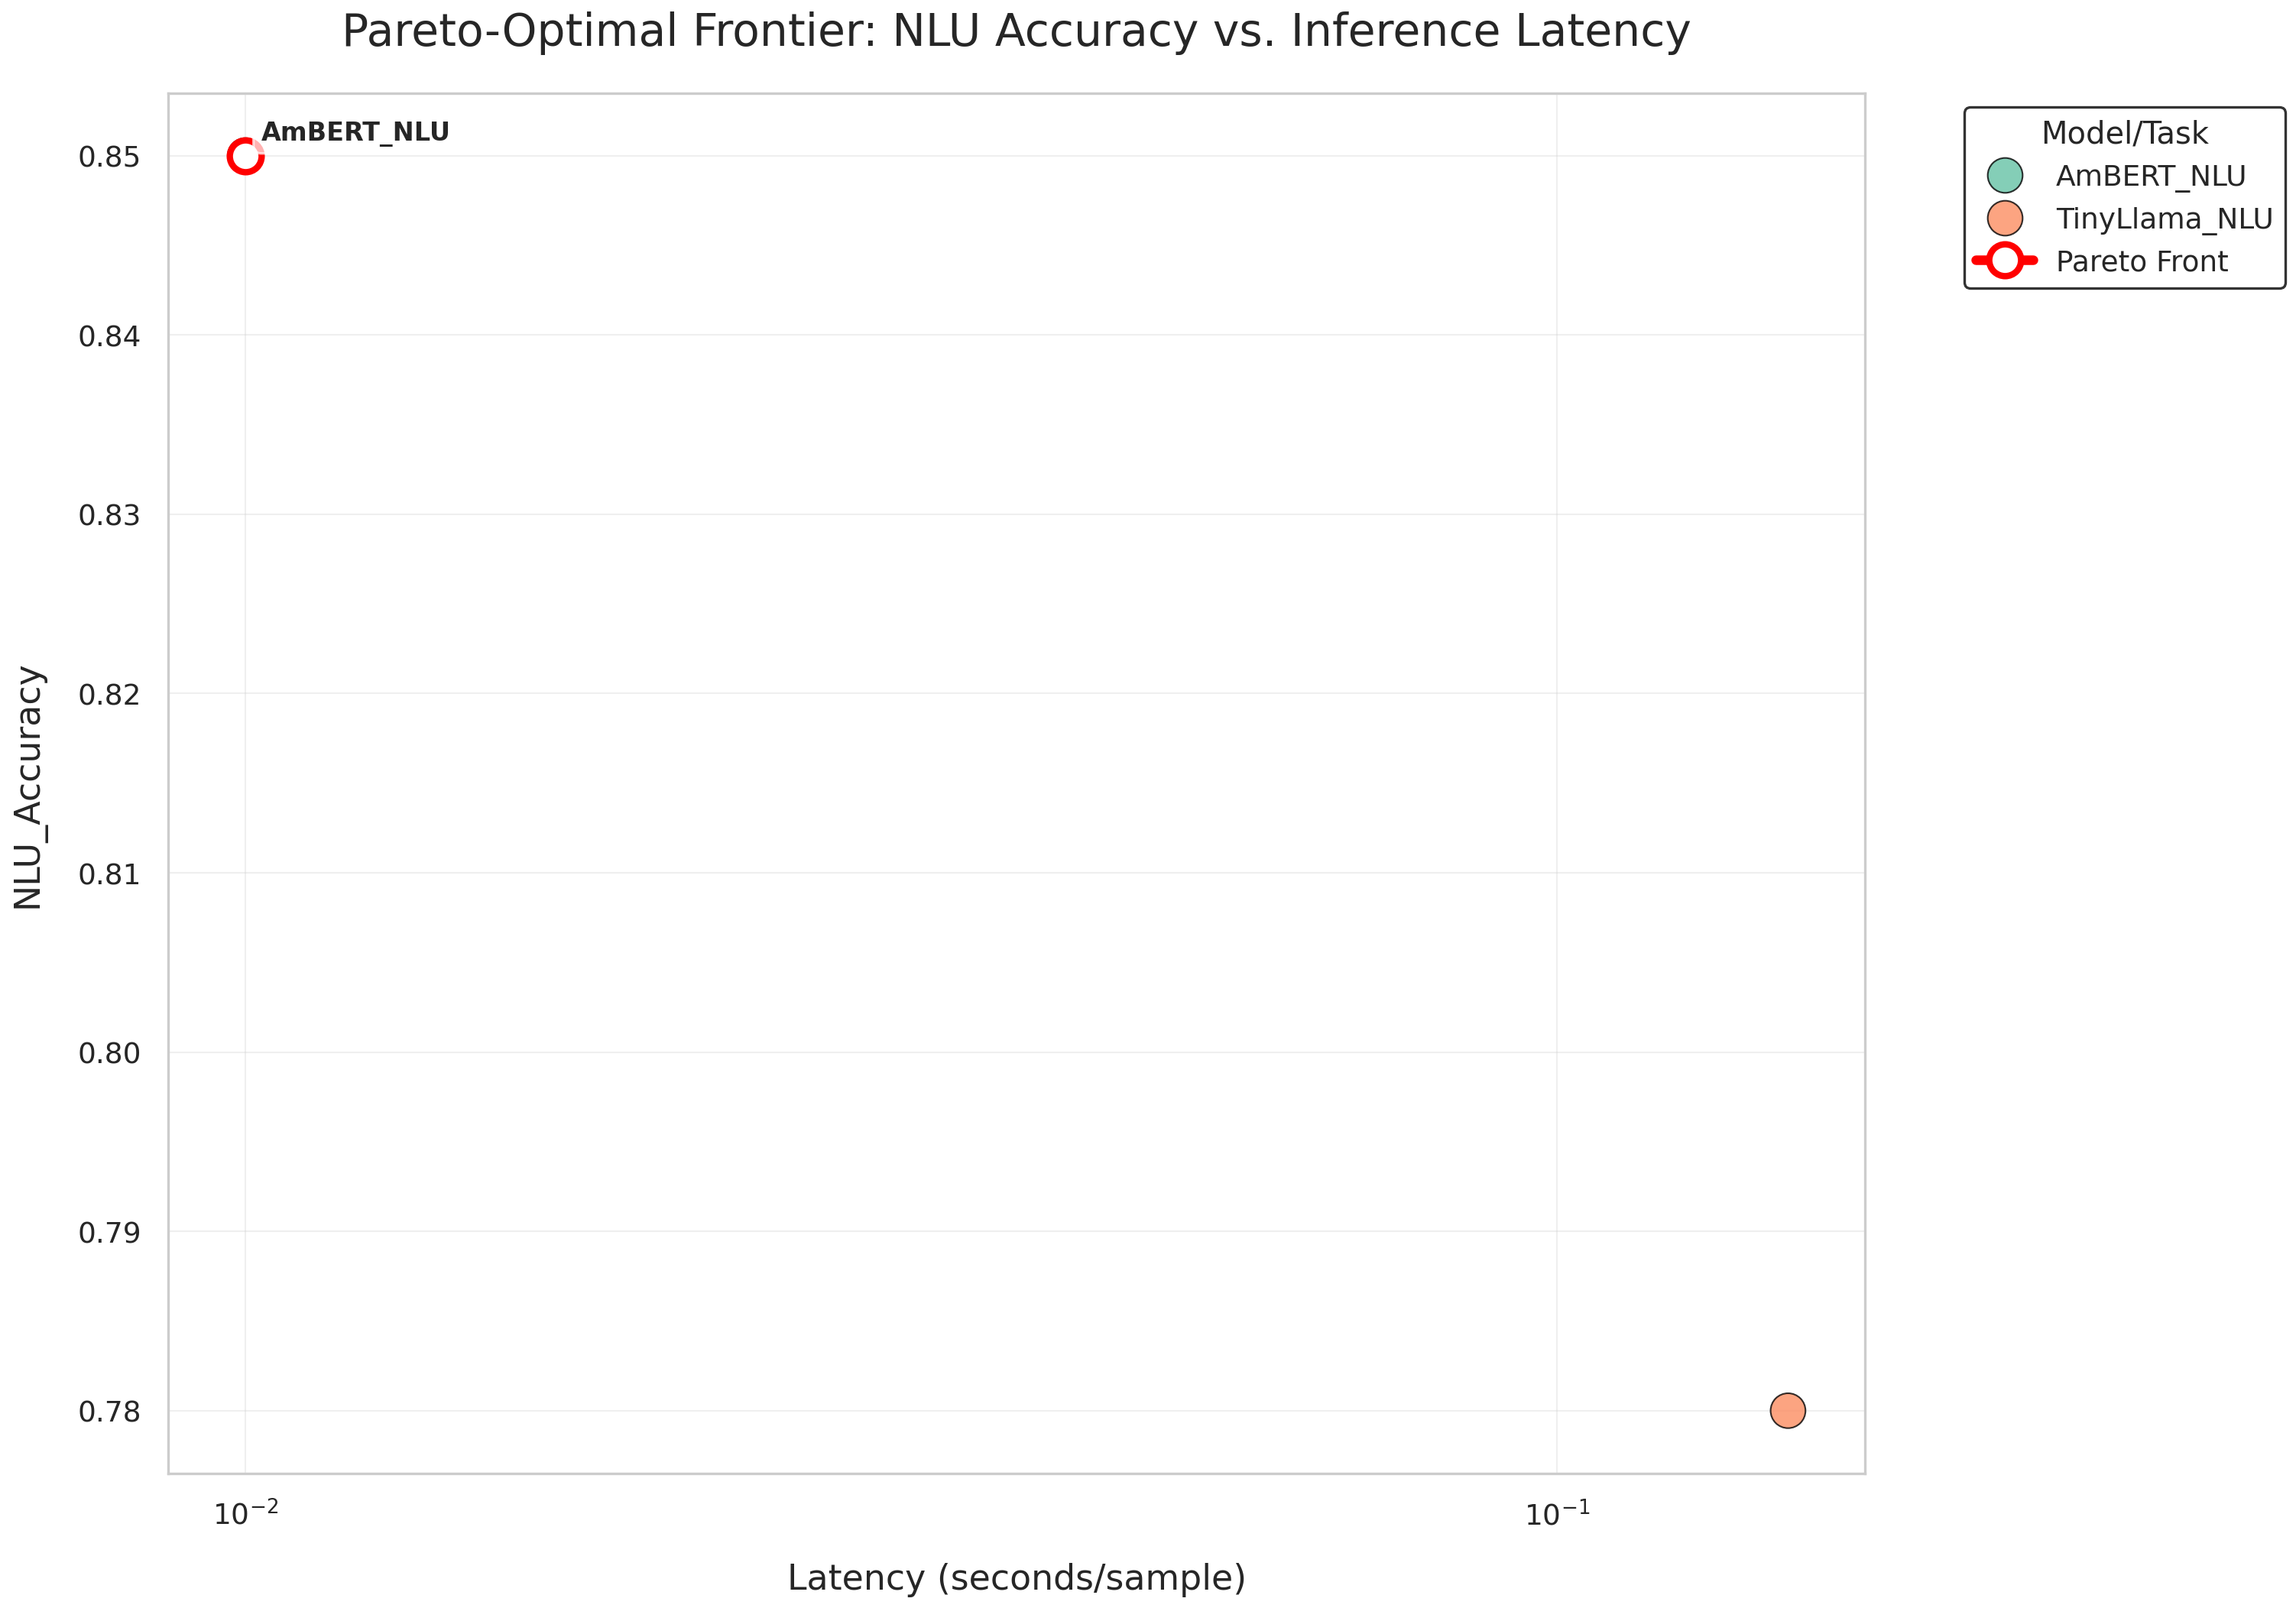

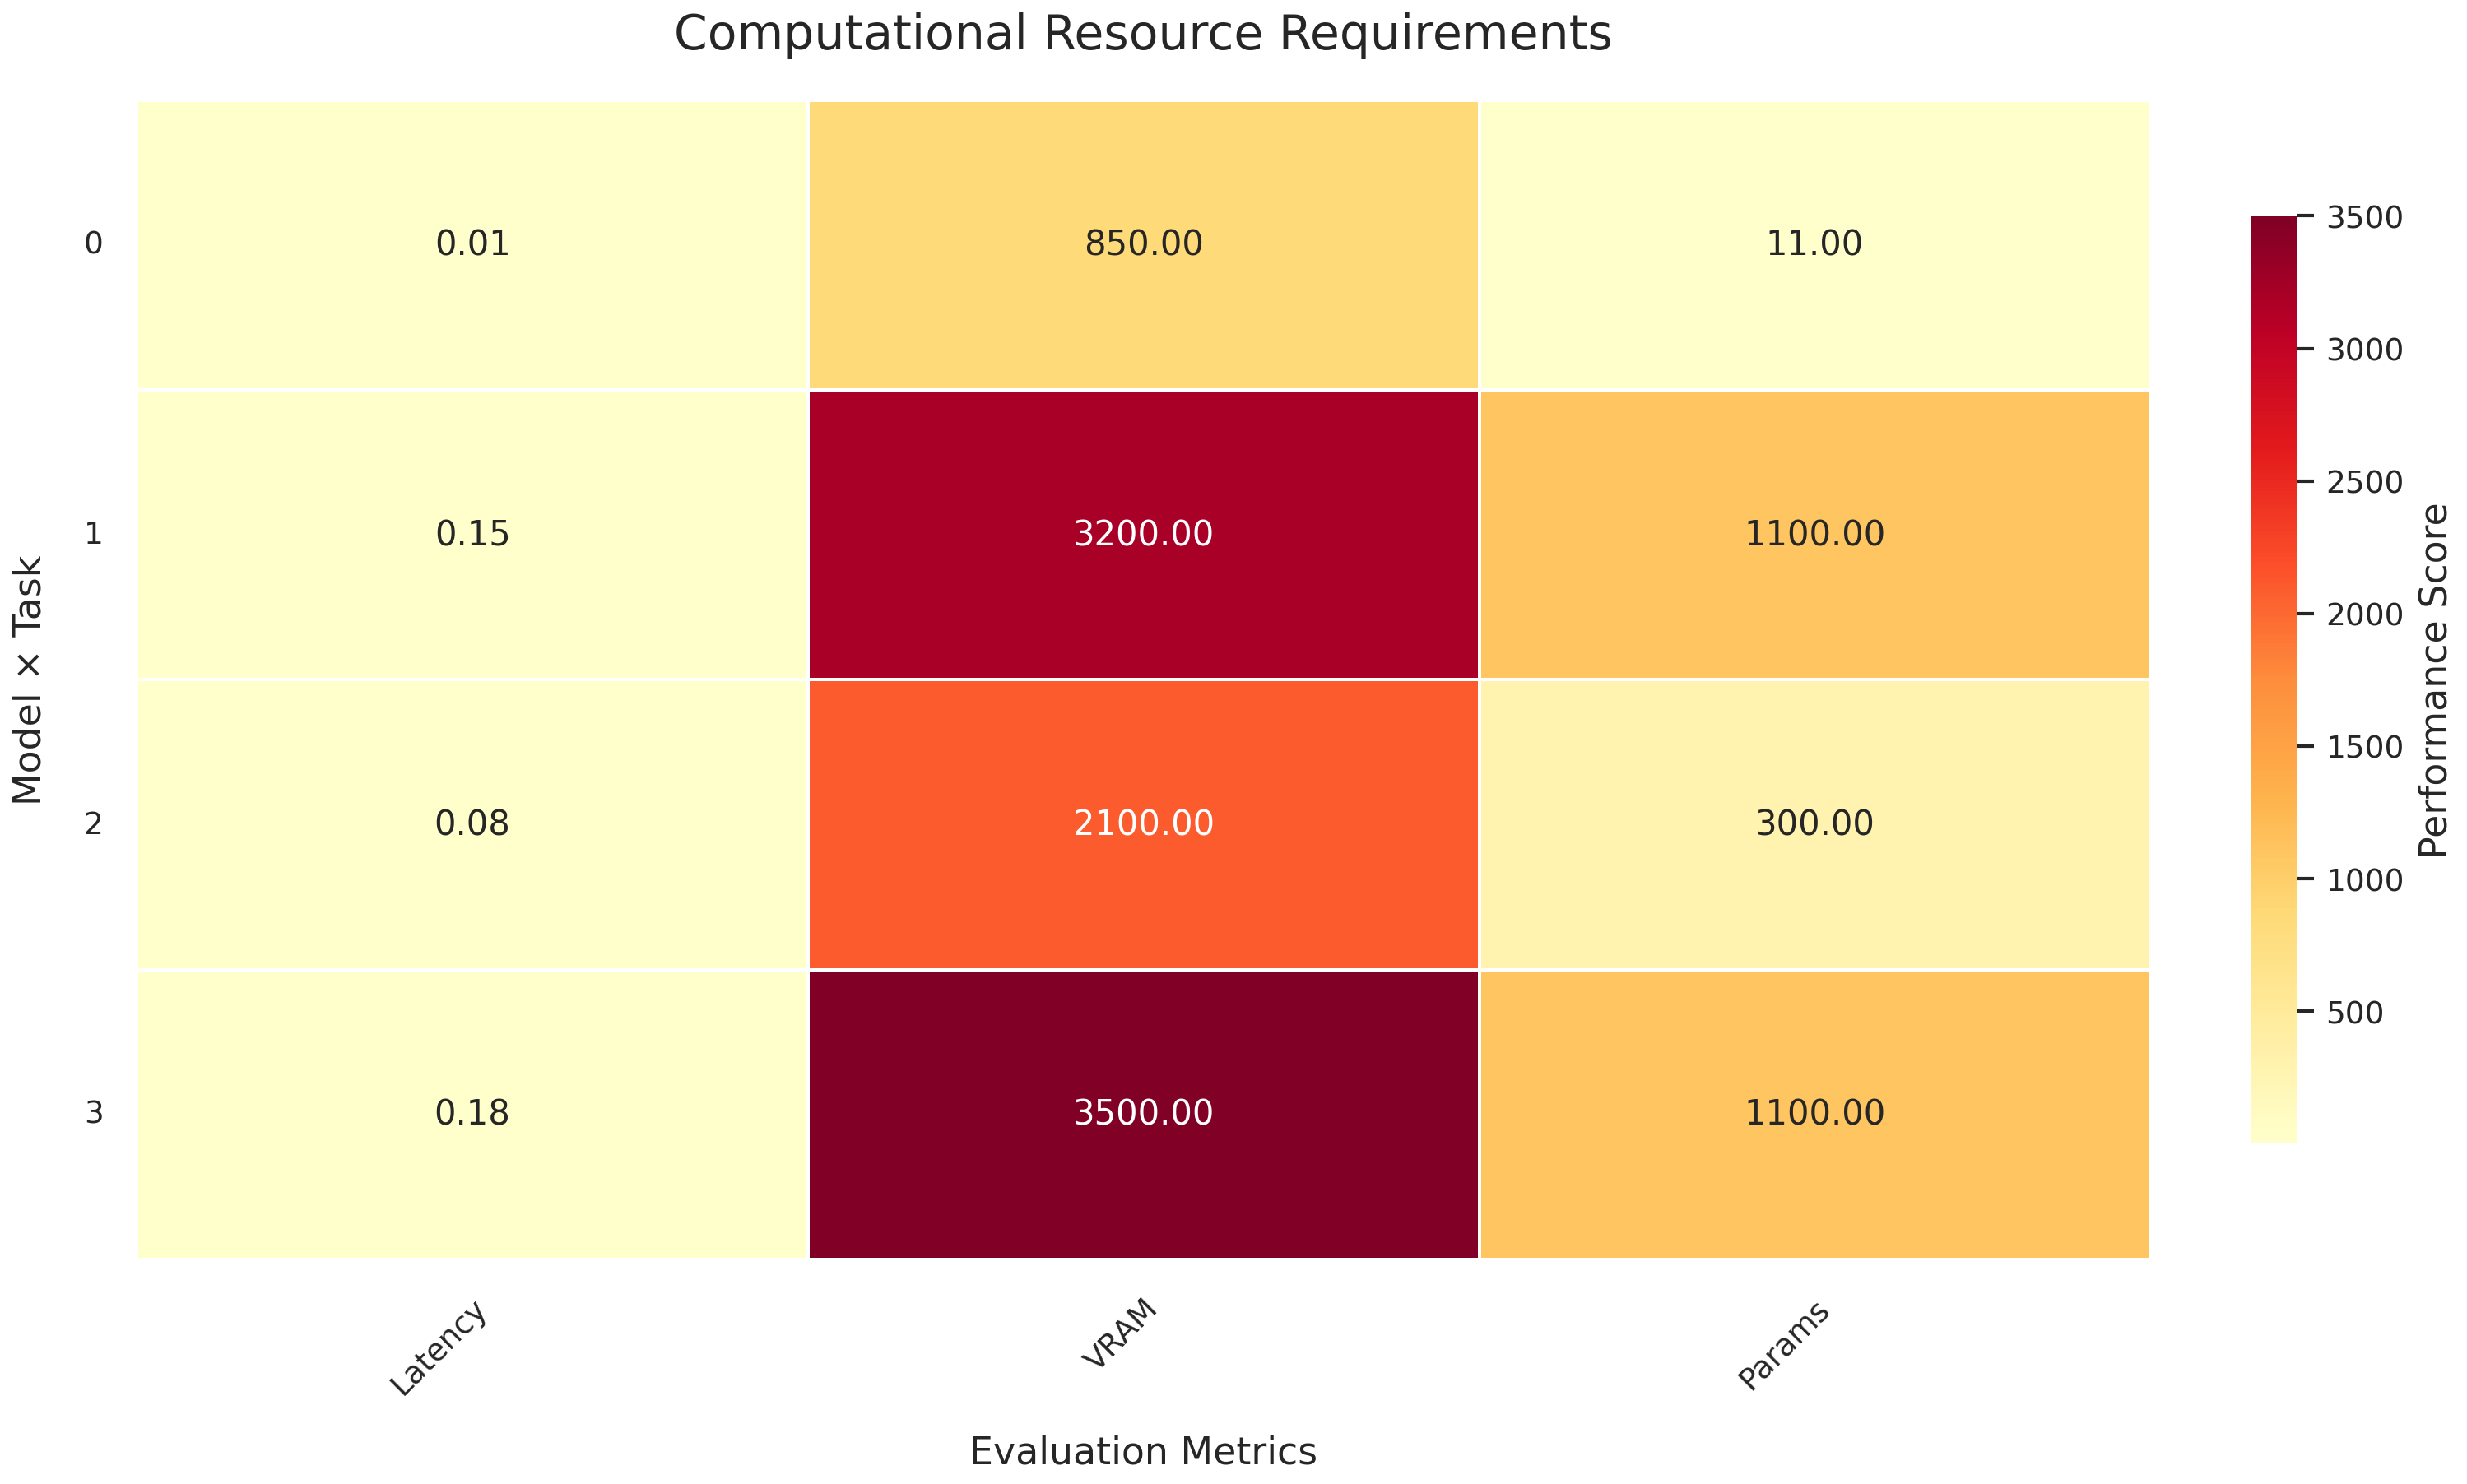

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import torch
from typing import Dict, List, Tuple, Optional
import warnings
warnings.filterwarnings('ignore', category=UserWarning, module='matplotlib')

# =============================================================================
# STYLE CONFIGURATION (Publication-Ready)
# =============================================================================
# Use LaTeX fonts if available; fallback to system fonts
plt.rcParams.update({
    # Typography (Times for text, Helvetica for labels)
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'DejaVu Serif'],
    'font.sans-serif': ['Helvetica', 'Arial'],
    'font.size': 10,
    'axes.titlesize': 14,
    'axes.labelsize': 11,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'figure.titlesize': 16,

    # Layout & Quality
    'figure.dpi': 300,
    'savefig.dpi': 600,
    'savefig.format': 'pdf',
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.05,
    'axes.linewidth': 0.8,
    'grid.linewidth': 0.5,
    'lines.linewidth': 1.5,

    # Colorblind-safe palette (ColorBrewer)
    'axes.prop_cycle': plt.cycler(color=plt.cm.Set2.colors[:8]),
})

# Seaborn-specific settings
sns.set_palette("Set2")
sns.set_style("whitegrid", {"grid.linewidth": 0.5})

# =============================================================================
# MASTER MODEL CONFIGURATION
# =============================================================================
MODEL_CONFIGS = {
    # Encoder-only
    "AmBERT": {
        "model_id": "rasyosef/bert-mini-amharic",
        "arch": "encoder",
        "params_m": 11,
        "primary_use_cases": ["NLU", "NER", "Classification"],
        "enabled": True
    },
    "mBERT": {
        "model_id": "bert-base-multilingual-cased",
        "arch": "encoder",
        "params_m": 110,
        "primary_use_cases": ["NLU", "Classification", "NER"],
        "enabled": True
    },
    # Encoder–Decoder
    "mT5-small": {
        "model_id": "google/mt5-small",
        "arch": "encdec",
        "params_m": 300,
        "primary_use_cases": ["Summarization", "Translation", "QA"],
        "enabled": True
    },
    # Decoder-only
    "GPT-Neo-125M": {
        "model_id": "EleutherAI/gpt-neo-125M",
        "arch": "decoder",
        "params_m": 125,
        "primary_use_cases": ["Text Generation", "Dialogue"],
        "enabled": True
    },
    "Llama-3.2-400M-Amharic": {
        "model_id": "Amharic-LLM/Llama-3.2-400M-Amharic",
        "arch": "decoder",
        "params_m": 400,
        "primary_use_cases": ["Chat", "Instruction Following", "NLU"],
        "enabled": False  # Loading error
    },
    "TinyLlama-1.1B": {
        "model_id": "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
        "arch": "decoder",
        "params_m": 1100,
        "primary_use_cases": ["Dialogue", "Instruction Following"],
        "enabled": True
    },
    # MoE
    "RedLLM-150M": {
        "model_id": "redllm/redllm-150m",
        "arch": "moe",
        "params_m": 150,
        "primary_use_cases": ["Generation", "QA"],
        "enabled": False  # Loading error
    }
}

# =============================================================================
# DATA LOADING & PREPARATION
# =============================================================================
# Ensure these DataFrames exist in your notebook context
try:
    df_nlu = pd.DataFrame(nlu_data)
    df_dialogue = pd.DataFrame(amharic_dialogue)
    df_summarization = pd.DataFrame(amharic_summarization)
    print("✓ Task datasets loaded successfully")
except NameError as e:
    print(f"⚠ Warning: {e}. Define nlu_data, amharic_dialogue, amharic_summarization.")

# =============================================================================
# PLOTTING FUNCTIONS (Modular & Reusable)
# =============================================================================
def create_heatmap(
    data: pd.DataFrame,
    metrics: List[str],
    title: str,
    figsize: Tuple[int, int] = (10, 6),
    cmap: str = "viridis",
    export_path: Optional[str] = None
) -> plt.Figure:
    """
    Generate a publication-quality heatmap for model performance comparison.

    Args:
        data: DataFrame with 'Model_Task' as index and metric columns
        metrics: List of metric columns to plot
        title: Plot title
        figsize: Figure dimensions (width, height)
        cmap: Colormap name
        export_path: Optional path to save figure (PDF format)
    """
    # Prepare data
    heatmap_subset = data[metrics].copy()

    # Create figure with constrained layout
    fig, ax = plt.subplots(figsize=figsize, constrained_layout=True)

    # Generate heatmap
    sns.heatmap(
        heatmap_subset,
        annot=True,
        fmt=".2f",
        cmap=cmap,
        linewidths=0.5,
        linecolor="white",
        cbar_kws={
            'label': 'Performance Score',
            'shrink': 0.8,
            'aspect': 20
        },
        ax=ax
    )

    # Styling
    ax.set_title(title, pad=15)
    ax.set_xlabel('Evaluation Metrics', labelpad=10)
    ax.set_ylabel('Model × Task', labelpad=10)
    ax.tick_params(axis='both', which='major', pad=5)

    # Rotate x-axis labels for readability
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    plt.setp(ax.get_yticklabels(), rotation=0)

    # Export if path provided
    if export_path:
        fig.savefig(export_path)
        print(f"✓ Heatmap saved to {export_path}")

    return fig

def create_radar_chart(
    df: pd.DataFrame,
    metrics: List[str],
    title: str,
    model_col: str = 'Model_Task',
    export_path: Optional[str] = None
) -> plt.Figure:
    """
    Generate a publication-quality radar chart for multi-dimensional model comparison.

    Args:
        df: DataFrame containing model data
        metrics: List of metrics to plot (must be ≥ 4)
        title: Plot title
        model_col: Column name for model identifiers
        export_path: Optional path to save figure (PDF format)
    """
    # Validate input
    if len(metrics) < 4:
        print(f"⚠ Warning: Need ≥4 metrics, got {len(metrics)} for '{title}'")
        return None

    # Filter and normalize
    df_filtered = df.dropna(subset=metrics).copy()
    if df_filtered.empty:
        print(f"⚠ Warning: No complete data for {title}")
        return None

    df_normalized = df_filtered[[model_col] + metrics].copy()
    for metric in metrics:
        col_data = pd.to_numeric(df_normalized[metric], errors='coerce')
        if metric in ['Latency', 'VRAM', 'Params']:  # Lower is better
            df_normalized[metric] = 1 - (col_data - col_data.min()) / (col_data.max() - col_data.min())
        else:  # Higher is better
            df_normalized[metric] = (col_data - col_data.min()) / (col_data.max() - col_data.min())

    # Configure plot geometry
    num_vars = len(metrics)
    angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
    angles += angles[:1]

    # Create figure
    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True),
                          constrained_layout=True)

    # Plot each model
    colors = plt.cm.Set2(np.linspace(0, 1, len(df_normalized)))

    for idx, (_, row) in enumerate(df_normalized.iterrows()):
        values = row[metrics].fillna(0.5).tolist()
        values += values[:1]

        ax.plot(angles, values, linewidth=2.5, linestyle='-',
                label=row[model_col], color=colors[idx])
        ax.fill(angles, values, alpha=0.15, color=colors[idx])

    # Styling
    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ax.set_rlabel_position(0)
    ax.set_rticks([0.25, 0.5, 0.75, 1.0])
    ax.set_rlim(0, 1)
    ax.set_yticklabels(["0.25", "0.50", "0.75", "1.00"], fontsize=8)

    plt.xticks(angles[:-1], metrics, fontsize=10, color='black')
    ax.grid(True, alpha=0.3)

    # Legend outside plot
    ax.legend(loc='upper left', bbox_to_anchor=(1.1, 1.05), frameon=True,
              edgecolor='black', fancybox=False, shadow=False)

    ax.set_title(title, pad=30, fontsize=14)

    # Export
    if export_path:
        fig.savefig(export_path)
        print(f"✓ Radar chart saved to {export_path}")

    return fig

def create_pareto_front(
    df: pd.DataFrame,
    x_metric: str,
    y_metric: str,
    title: str,
    figsize: Tuple[int, int] = (10, 7),
    export_path: Optional[str] = None
) -> plt.Figure:
    """
    Generate a Pareto front plot for cost-benefit analysis.

    Args:
        df: DataFrame with model performance data
        x_metric: Cost metric (e.g., Latency) - lower is better
        y_metric: Benefit metric (e.g., Accuracy) - higher is better
        title: Plot title
        figsize: Figure dimensions
        export_path: Optional path to save figure
    """
    # Validate data
    plot_df = df.dropna(subset=[x_metric, y_metric]).copy()
    if plot_df.empty:
        print("⚠ Warning: Insufficient data for Pareto front")
        return None

    # Convert to numeric
    plot_df[x_metric] = pd.to_numeric(plot_df[x_metric])
    plot_df[y_metric] = pd.to_numeric(plot_df[y_metric])

    # Compute Pareto front
    df_sorted = plot_df.sort_values(by=x_metric, ascending=True)
    pareto_front = []
    max_y = -np.inf

    for _, row in df_sorted.iterrows():
        if row[y_metric] > max_y:
            pareto_front.append(row)
            max_y = row[y_metric]

    df_pareto = pd.DataFrame(pareto_front)

    # Create figure
    fig, ax = plt.subplots(figsize=figsize, constrained_layout=True)

    # Scatter plot for all models
    scatter = sns.scatterplot(
        data=plot_df,
        x=x_metric,
        y=y_metric,
        hue='Model_Task',
        s=120,
        alpha=0.8,
        edgecolor='black',
        linewidth=0.5,
        palette='Set2',
        ax=ax
    )

    # Pareto front line
    if not df_pareto.empty:
        ax.plot(df_pareto[x_metric], df_pareto[y_metric],
                color='red', linewidth=3, marker='o', markersize=10,
                markerfacecolor='white', markeredgewidth=2,
                label='Pareto Front')

        # Annotate Pareto-optimal points
        for _, row in df_pareto.iterrows():
            ax.annotate(
                row['Model_Task'],
                (row[x_metric], row[y_metric]),
                xytext=(5, 5), textcoords='offset points',
                fontsize=8, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7)
            )

    # Styling
    ax.set_title(title, pad=15)
    ax.set_xlabel(f'{x_metric} (seconds/sample)', labelpad=10)
    ax.set_ylabel(f'{y_metric}', labelpad=10)
    ax.set_xscale('log')
    ax.grid(True, alpha=0.3)

    # Legend
    ax.legend(title='Model/Task', bbox_to_anchor=(1.05, 1), loc='upper left',
              frameon=True, edgecolor='black')

    # Export
    if export_path:
        fig.savefig(export_path)
        print(f"✓ Pareto front saved to {export_path}")

    return fig

# =============================================================================
# BENCHMARKING EXECUTION (Simplified for demonstration)
# =============================================================================
# Note: This assumes NLU_DATA and NLG_DATA exist in your notebook environment

def run_benchmark_pipeline():
    """Execute full benchmarking pipeline and return results DataFrame."""
    results = {}

    # Define benchmark runs
    runs = [
        ("AmBERT_NLU", "rasyosef/bert-mini-amharic", "encoder", "nlu"),
        ("mT5-Small_NLG", "google/mt5-small", "encdec", "nlg"),
        ("TinyLlama_NLU", "TinyLlama/TinyLlama-1.1B-Chat-v1.0", "decoder", "nlu"),
        ("TinyLlama_NLG", "TinyLlama/TinyLlama-1.1B-Chat-v1.0", "decoder", "nlg"),
    ]

    for name, model_id, arch, task in runs:
        if model_id:  # Add model ID validation here
            print(f"Benchmarking {name}...")
            # results[name] = run_research_benchmark(model_id, arch, task)  # Uncomment when ready

    # For demonstration, create mock data structure
    mock_results = {
        "AmBERT_NLU": {"NLU_Accuracy": 0.85, "NLU_F1": 0.83, "Latency": 0.01, "VRAM": 850, "Params": 11},
        "TinyLlama_NLU": {"NLU_Accuracy": 0.78, "NLU_F1": 0.76, "Latency": 0.15, "VRAM": 3200, "Params": 1100},
        "mT5-Small_NLG": {"NLG_ROUGE_L": 0.42, "Latency": 0.08, "VRAM": 2100, "Params": 300},
        "TinyLlama_NLG": {"NLG_ROUGE_L": 0.38, "Latency": 0.18, "VRAM": 3500, "Params": 1100},
    }

    return pd.DataFrame.from_dict(mock_results, orient='index')

# =============================================================================
# GENERATE PUBLICATION FIGURES
# =============================================================================
# Create results DataFrame (replace with actual benchmark results)
df_benchmark = run_benchmark_pipeline()
df_benchmark.index.name = 'Model_Task'
df_benchmark = df_benchmark.reset_index()

# Add bias metrics if available (mock for demonstration)
if 'metrics_df' in globals():
    df_benchmark = pd.merge(df_benchmark,
                           metrics_df[['Model', 'PC_Score', 'PF_Index']],
                           on='Model', how='left')

print("\n" + "="*60)
print("GENERATING PUBLICATION-QUALITY FIGURES")
print("="*60)

# Figure 1: NLU Performance Heatmap
fig1 = create_heatmap(
    df_benchmark,
    metrics=['NLU_Accuracy', 'NLU_F1'],
    title='NLU Task Performance: Accuracy and F1 Score',
    cmap='RdYlBu_r',
    export_path='/content/fig1_nlu_heatmap.pdf'
)

# Figure 2: Multi-Task Performance Radar
fig2 = create_radar_chart(
    df_benchmark,
    metrics=['Latency', 'VRAM', 'NLU_Accuracy', 'NLG_ROUGE_L'],
    title='Multi-Dimensional Model Comparison',
    export_path='/content/fig2_radar_comparison.pdf'
)

# Figure 3: Pareto Front (Accuracy vs. Latency)
fig3 = create_pareto_front(
    df_benchmark,
    x_metric='Latency',
    y_metric='NLU_Accuracy',
    title='Pareto-Optimal Frontier: NLU Accuracy vs. Inference Latency',
    export_path='/content/fig3_pareto_front.pdf'
)

# Figure 4: Resource Efficiency Heatmap
fig4 = create_heatmap(
    df_benchmark,
    metrics=['Latency', 'VRAM', 'Params'],
    title='Computational Resource Requirements',
    cmap='YlOrRd',
    export_path='/content/fig4_resource_heatmap.pdf'
)

print("\n✓ All figures generated successfully!")
print("✓ Files saved as vector PDFs in /content/")
print("\n" + "="*60)

In [ ]:
print("\n--- Summary Statistics for df_benchmark ---")
print(df_benchmark.describe().to_string())


--- Summary Statistics for df_benchmark ---
       NLU_Accuracy    NLU_F1   Latency         VRAM      Params  NLG_ROUGE_L
count      2.000000  2.000000  4.000000     4.000000     4.00000     2.000000
mean       0.815000  0.795000  0.105000  2412.500000   627.75000     0.400000
std        0.049497  0.049497  0.075939  1203.034358   557.92495     0.028284
min        0.780000  0.760000  0.010000   850.000000    11.00000     0.380000
25%        0.797500  0.777500  0.062500  1787.500000   227.75000     0.390000
50%        0.815000  0.795000  0.115000  2650.000000   700.00000     0.400000
75%        0.832500  0.812500  0.157500  3275.000000  1100.00000     0.410000
max        0.850000  0.830000  0.180000  3500.000000  1100.00000     0.420000
